<a href="https://colab.research.google.com/github/mauricioechavarriapulgarin-tech/Programaci-n_aplicada_retos/blob/main/Reto2_procesamiento_imagenes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Imágenes y matrices
import numpy as np
import cv2
from google.colab.patches import cv2_imshow
import os

# Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
rutabase = '/content/drive/MyDrive/Imagen_trabajo'

In [ ]:
# Definir imagen a leer
nombre = 'Imagen_trabajo.jpg'
rutaimagen = os.path.join(rutabase, nombre)
print(rutaimagen)

/content/drive/MyDrive/Imagen_trabajo/Imagen_trabajo.jpg


In [ ]:
# Leer imagen y mostrar información
img = cv2.imread(rutaimagen, 1)  # 1 = imagen a color

print('Alto (num filas), Ancho (num col), Canales:', img.shape)

Alto (num filas), Ancho (num col), Canales: (408, 612, 3)


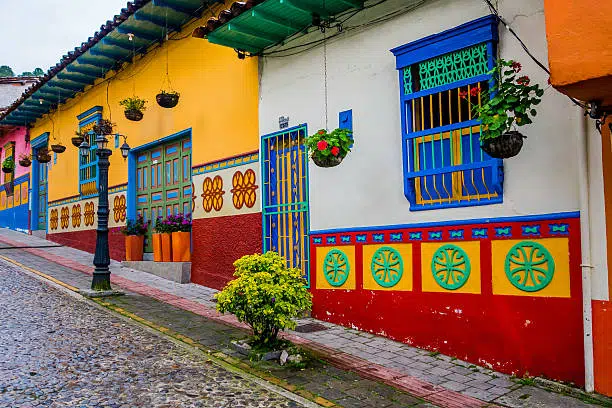

In [ ]:
# Mostrar imagen
cv2_imshow(img)

In [ ]:
# Definir coordenadas de las ROI
ROI1 = (200, 90, 240, 145)
ROI2 = (200, 225, 225, 260)
ROI3 = (320, 170, 375, 220)
ROI4 = (235, 20, 273, 42)
ROI5 = (560, 16, 600, 70)
ROI6 = (390, 195, 440, 260)

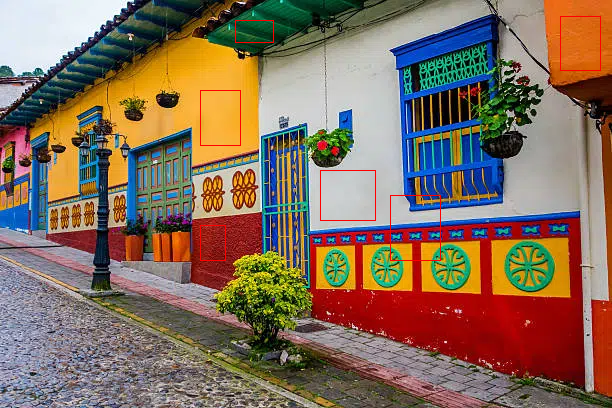

In [ ]:
# Dibujar los rectángulos
for ROI in [ROI1, ROI2, ROI3, ROI4, ROI5, ROI6]:
    cv2.rectangle(img, ROI[:2], ROI[2:], (0, 0, 255), 1)

cv2_imshow(img)

ROI 1


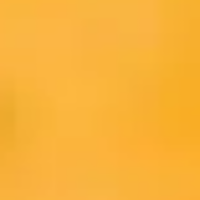

ROI 2


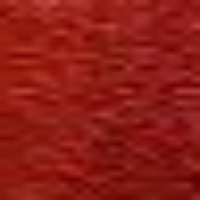

ROI 3


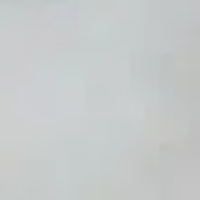

ROI 4


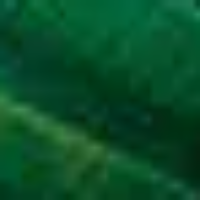

ROI 5


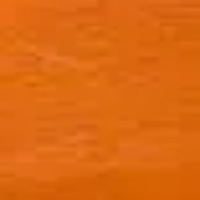

ROI 6


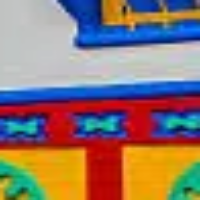

In [ ]:
# Recortar las ROI
recortes = [img[y1+1:y2, x1+1:x2] for x1, y1, x2, y2 in
            [ROI1, ROI2, ROI3, ROI4, ROI5, ROI6]]

# Ampliar y mostrar
for i, roi in enumerate(recortes, 1):
    print(f"ROI {i}")
    cv2_imshow(cv2.resize(roi, (200, 200)))

In [ ]:
# Calcular estadísticas de las ROI
medias, desviaciones = [], []

for i, roi in enumerate(recortes, 1):
    media = np.mean(roi, axis=(0, 1))
    std = np.std(roi, axis=(0, 1))
    medias.append(media)
    desviaciones.append(std)
    print(f"ROI {i}\nMedia BGR: {media.round(2)}")
    print(f"Desviación estándar BGR: {std.round(2)}")

ROI 1
Media BGR: [ 57.71 178.85 249.56]
Desviación estándar BGR: [7.99 2.8  2.4 ]
ROI 2
Media BGR: [ 21.44  28.   142.25]
Desviación estándar BGR: [13.63 13.97 16.66]
ROI 3
Media BGR: [202.21 201.96 198.72]
Desviación estándar BGR: [4.87 4.14 3.84]
ROI 4
Media BGR: [40.62 77.75  8.26]
Desviación estándar BGR: [13.23 18.95 12.07]
ROI 5
Media BGR: [ 17.67 104.04 220.52]
Desviación estándar BGR: [6.95 5.19 5.42]
ROI 6
Media BGR: [112.58 118.7  141.43]
Desviación estándar BGR: [82.83 73.08 82.31]


In [ ]:
# Sumar las desviaciones estándar de cada ROI
tabla_resultados["DE suma"] = tabla_resultados[["DE B", "DE G", "DE R"]].sum(axis=1)

display(tabla_resultados)

,ROI,Media B,Media G,Media R,DE B,DE G,DE R,DE promedio,DE suma
0,ROI 1,57.71,178.85,249.56,7.99,2.80,2.40,4.40,13.19
1,ROI 2,21.44,28.00,142.25,13.63,13.97,16.66,14.75,44.26
2,ROI 3,202.21,201.96,198.72,4.87,4.14,3.84,4.28,12.85
3,ROI 4,40.62,77.75,8.26,13.23,18.95,12.07,14.75,44.25
4,ROI 5,17.67,104.04,220.52,6.95,5.19,5.42,5.86,17.56
5,ROI 6,112.58,118.70,141.43,82.83,73.08,82.31,79.41,238.22


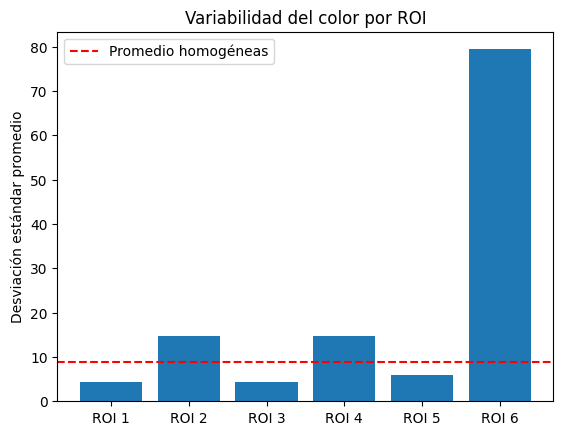

In [ ]:
# Gráfica de variabilidad

import matplotlib.pyplot as plt

de = tabla_resultados["DE promedio"]
plt.bar(tabla_resultados["ROI"], de)
plt.axhline(de.iloc[:5].mean(), color="red", linestyle="--", label="Promedio homogéneas")
plt.ylabel("Desviación estándar promedio")
plt.title("Variabilidad del color por ROI")
plt.legend()
plt.show()